In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

df = pd.read_csv("listings.csv")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Rows: 17,713
Columns: 19


In [2]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (17713, 19)


,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,69824,2 bd/2ba Oceanfront Condo,"351,303.00","1,462,516,387,356,198,656.00",Tracy,NaN,Hallandale Beach,25.98,-80.12,Entire home/apt,164.00,30.00,4,2023-06-03,0.06,2.00,336,0,NaN
1,83449,2 miles from the beach 2/1 sleeps 5 #204,"454,736.00","1,462,518,834,043,238,656.00",Jon,NaN,Dania Beach,26.03,-80.14,Entire home/apt,148.00,3.00,37,2026-04-16,0.21,17.00,18,3,NaN
2,129099,MIAMI - AMAZING APARTMENT OCEANVIEW,"637,272.00","1,462,524,468,792,196,608.00",Bianca,NaN,Hollywood,25.99,-80.12,Entire home/apt,344.00,6.00,29,2026-04-12,0.16,5.00,365,1,NaN
3,143335,2BR/2BT Lakeview Ground (Max 4 adults + 4 kids),"691,894.00","1,462,513,575,223,727,616.00",Karlene,NaN,Plantation,26.13,-80.29,Entire home/apt,265.00,2.00,7,2026-06-23,2.26,3.00,316,7,NaN
4,191160,Tropical Beach Paradise Awaits You,"924,482.00","1,462,533,402,004,157,952.00",Dan,NaN,Deerfield Beach,26.31,-80.08,Entire home/apt,376.00,2.00,25,2019-11-08,0.14,1.00,179,0,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17713 entries, 0 to 17712
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              17713 non-null  int64  
 1   name                            17713 non-null  str    
 2   host_id                         17698 non-null  float64
 3   host_profile_id                 17695 non-null  float64
 4   host_name                       17696 non-null  str    
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   17713 non-null  str    
 7   latitude                        17713 non-null  float64
 8   longitude                       17713 non-null  float64
 9   room_type                       17713 non-null  str    
 10  price                           16516 non-null  float64
 11  minimum_nights                  17711 non-null  float64
 12  number_of_reviews               17713 non-n

In [4]:
dtype_summary = (
    df.dtypes.astype(str)
      .value_counts()
      .rename_axis("data_type")
      .reset_index(name="column_count")
)
dtype_summary

,data_type,column_count
0,float64,9
1,str,6
2,int64,4


In [5]:
print(f"Fully duplicated rows: {df.duplicated().sum():,}")
print(f"Duplicated listing IDs: {df['id'].duplicated().sum():,}")
print(f"Unique listing IDs: {df['id'].nunique():,}")

Fully duplicated rows: 0
Duplicated listing IDs: 0
Unique listing IDs: 17,713


In [6]:
missing = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100
    })
    .sort_values("missing_percent", ascending=False)
)

missing

,missing_count,missing_percent
neighbourhood_group,17713,100.00
license,17711,99.99
reviews_per_month,3456,19.51
last_review,3456,19.51
price,1197,6.76
host_profile_id,18,0.10
host_name,17,0.10
host_id,15,0.08
calculated_host_listings_count,15,0.08
minimum_nights,2,0.01


In [7]:
eda = df.copy()

# Convert the neighborhood ZIP code to text so it is treated as a category.
eda["neighbourhood"] = eda["neighbourhood"].astype(str)

# Convert last_review to a date.
eda["last_review"] = pd.to_datetime(eda["last_review"], errors="coerce")

# Keep only columns that contain at least one non-missing value for general analysis.
usable_columns = [col for col in eda.columns if not eda[col].isna().all()]

print("Usable columns:")
print(usable_columns)

Usable columns:
['id', 'name', 'host_id', 'host_profile_id', 'host_name', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'license']


In [8]:
numeric_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

existing_numeric = [c for c in numeric_columns if c in eda.columns]
eda[existing_numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
price,"16,516.00",392.06,"1,479.36",5.00,170.00,262.00,421.00,"115,854.00"
minimum_nights,"17,711.00",4.62,17.71,1.00,1.00,2.00,3.00,700.00
number_of_reviews,"17,713.00",39.73,74.16,0.00,1.00,13.00,49.00,"1,972.00"
reviews_per_month,"14,257.00",1.53,1.67,0.01,0.40,1.04,2.15,36.07
calculated_host_listings_count,"17,698.00",27.79,59.36,1.00,1.00,5.00,23.00,331.00
availability_365,"17,713.00",249.24,114.28,0.00,170.00,291.00,349.00,365.00
number_of_reviews_ltm,"17,713.00",10.68,16.92,0.00,0.00,4.00,16.00,613.00


In [9]:
neighborhood_counts = eda["neighbourhood"].value_counts().sort_values(ascending=False)
neighborhood_counts.to_frame("listing_count")

,listing_count
neighbourhood,
Fort Lauderdale,4600
Hollywood,4327
Pompano Beach,2113
Hallandale Beach,1744
Deerfield Beach,772
Dania Beach,578
Wilton Manors,517
Lauderdale By The Sea,493
Oakland Park,456


In [10]:
room_counts = eda["room_type"].value_counts()
display(room_counts.to_frame("listing_count"))

,listing_count
room_type,
Entire home/apt,14771
Private room,2594
Hotel room,227
Shared room,121


count    16,516.00
mean        392.06
std       1,479.36
min           5.00
25%         170.00
50%         262.00
75%         421.00
max     115,854.00
Name: price, dtype: float64


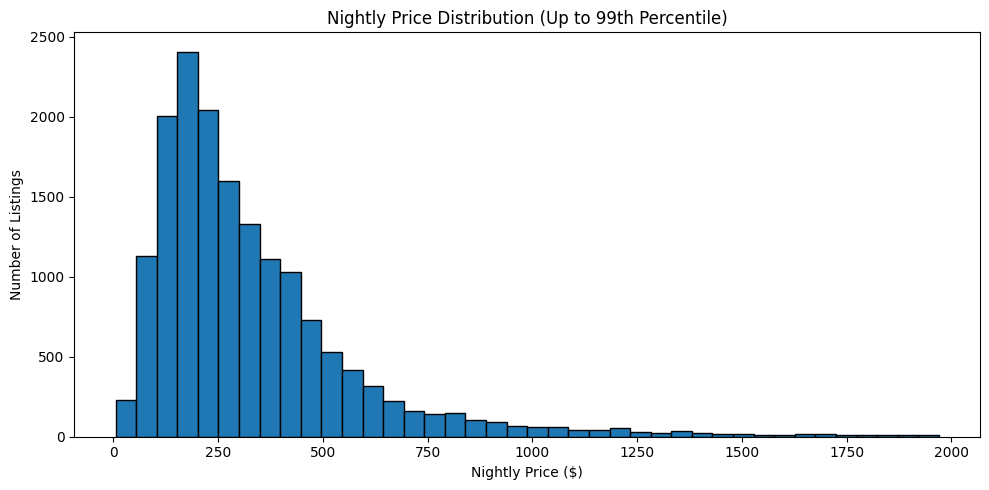

99th percentile price: $1,980.20


In [11]:
valid_prices = eda.loc[eda["price"] > 0, "price"].dropna()

print(valid_prices.describe())

price_99 = valid_prices.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(valid_prices[valid_prices <= price_99], bins=40, edgecolor="black")
plt.xlabel("Nightly Price ($)")
plt.ylabel("Number of Listings")
plt.title("Nightly Price Distribution (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

print(f"99th percentile price: ${price_99:,.2f}")

In [12]:
price_by_room = (
    eda.loc[eda["price"] > 0]
       .groupby("room_type")["price"]
       .agg(["count", "mean", "median", "min", "max"])
       .sort_values("median", ascending=False)
)

price_by_room

,count,mean,median,min,max
room_type,,,,,
Hotel room,225,576.86,346.00,93.00,"3,791.00"
Entire home/apt,13794,416.94,287.00,5.00,"115,854.00"
Private room,2376,246.44,142.00,7.00,"70,081.00"
Shared room,121,71.10,54.00,23.00,374.00


In [13]:
price_by_neighborhood = (
    eda.loc[eda["price"] > 0]
       .groupby("neighbourhood")["price"]
       .agg(["count", "mean", "median"])
       .sort_values("median", ascending=False)
)

price_by_neighborhood

,count,mean,median
neighbourhood,,,
Southwest Ranches,37,"1,035.24",579.00
Lazy Lake,4,565.75,522.00
Lighthouse Point,78,695.59,498.00
Parkland,19,623.58,468.00
County Regional Facility,3,"2,935.00",395.00
Tribal Land,6,389.67,362.00
Plantation,133,496.17,335.00
Hollywood,4124,380.88,300.00
Wilton Manors,492,347.55,286.00


count   17,711.00
mean         4.62
std         17.71
min          1.00
25%          1.00
50%          2.00
75%          3.00
max        700.00
Name: minimum_nights, dtype: float64


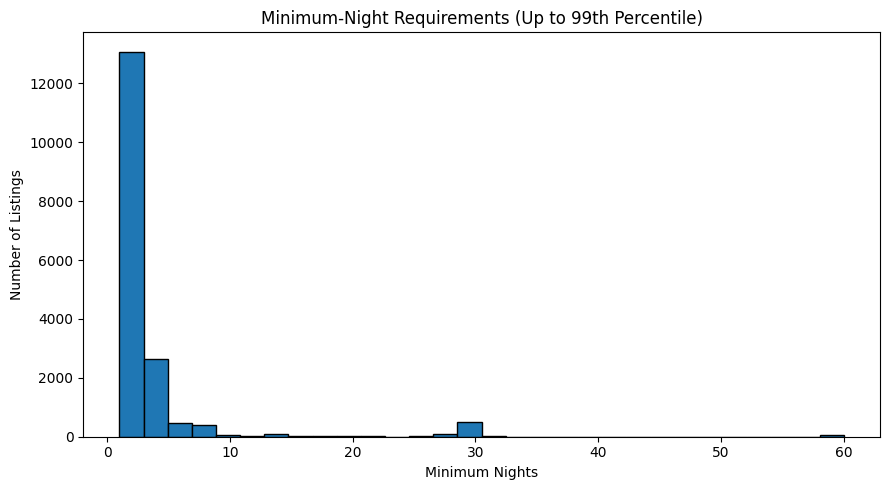

In [14]:
minimum_nights = eda["minimum_nights"].dropna()
upper_limit = minimum_nights.quantile(0.99)

print(minimum_nights.describe())

plt.figure(figsize=(9, 5))
plt.hist(minimum_nights[minimum_nights <= upper_limit], bins=30, edgecolor="black")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.title("Minimum-Night Requirements (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

In [15]:
review_summary = eda[
    ["number_of_reviews", "reviews_per_month", "number_of_reviews_ltm"]
].describe().T

review_summary

,count,mean,std,min,25%,50%,75%,max
number_of_reviews,"17,713.00",39.73,74.16,0.00,1.00,13.00,49.00,"1,972.00"
reviews_per_month,"14,257.00",1.53,1.67,0.01,0.40,1.04,2.15,36.07
number_of_reviews_ltm,"17,713.00",10.68,16.92,0.00,0.00,4.00,16.00,613.00


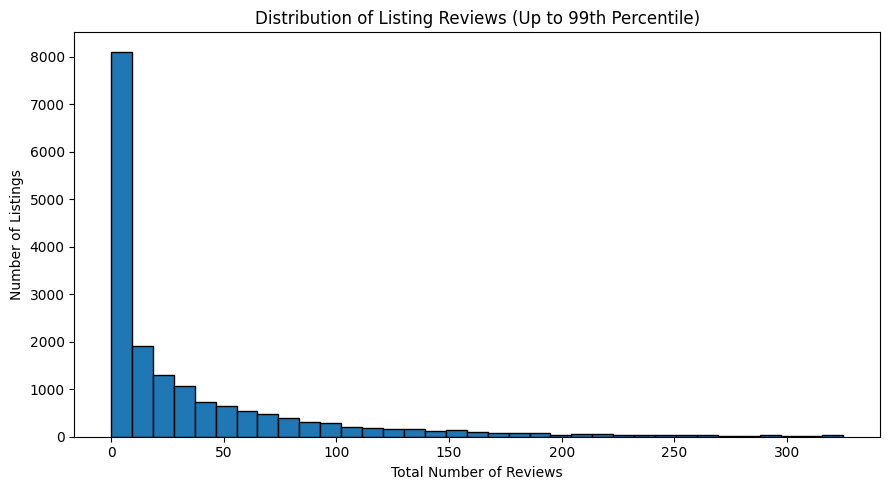

In [16]:
reviews = eda["number_of_reviews"].dropna()
review_99 = reviews.quantile(0.99)

plt.figure(figsize=(9, 5))
plt.hist(reviews[reviews <= review_99], bins=35, edgecolor="black")
plt.xlabel("Total Number of Reviews")
plt.ylabel("Number of Listings")
plt.title("Distribution of Listing Reviews (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

count   17,713.00
mean       249.24
std        114.28
min          0.00
25%        170.00
50%        291.00
75%        349.00
max        365.00
Name: availability_365, dtype: float64


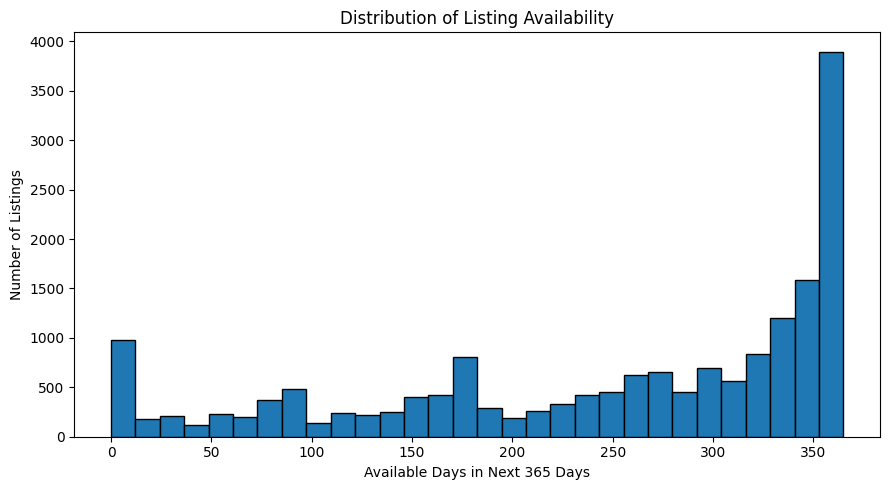

In [17]:
print(eda["availability_365"].describe())

plt.figure(figsize=(9, 5))
plt.hist(eda["availability_365"].dropna(), bins=30, edgecolor="black")
plt.xlabel("Available Days in Next 365 Days")
plt.ylabel("Number of Listings")
plt.title("Distribution of Listing Availability")
plt.tight_layout()
plt.show()

count   17,698.00
mean        27.79
std         59.36
min          1.00
25%          1.00
50%          5.00
75%         23.00
max        331.00
Name: calculated_host_listings_count, dtype: float64


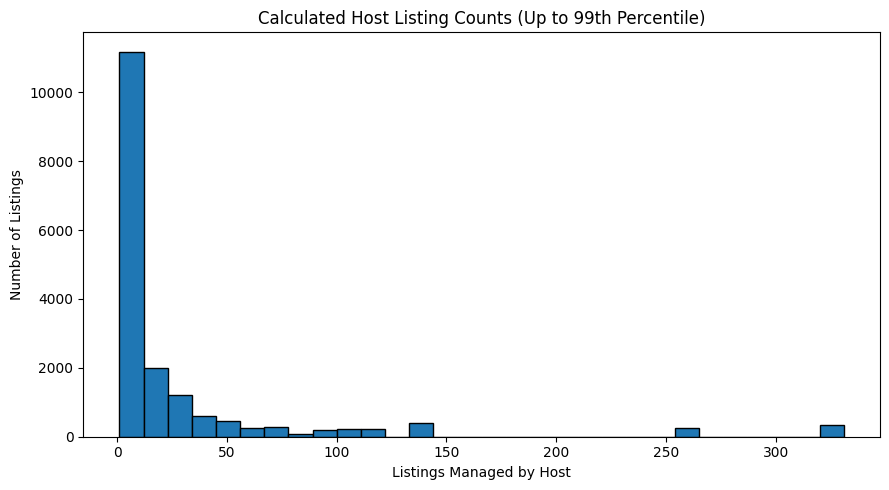

In [18]:
host_counts = eda["calculated_host_listings_count"].dropna()
host_99 = host_counts.quantile(0.99)

print(host_counts.describe())

plt.figure(figsize=(9, 5))
plt.hist(host_counts[host_counts <= host_99], bins=30, edgecolor="black")
plt.xlabel("Listings Managed by Host")
plt.ylabel("Number of Listings")
plt.title("Calculated Host Listing Counts (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

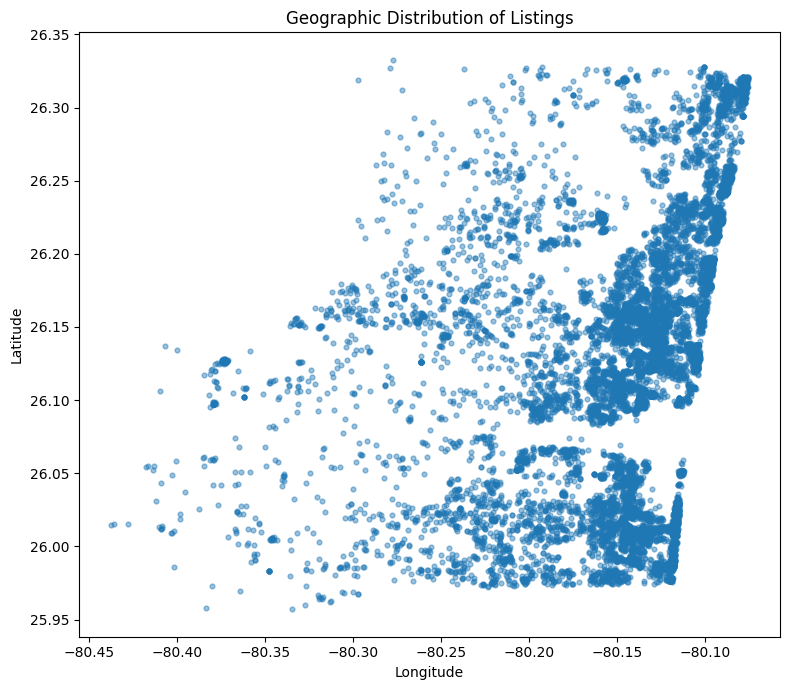

Latitude range:
25.95702 to 26.33263

Longitude range:
-80.43753 to -80.07531


In [19]:
plt.figure(figsize=(8, 7))
plt.scatter(
    eda["longitude"],
    eda["latitude"],
    s=12,
    alpha=0.45
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Listings")
plt.tight_layout()
plt.show()

print("Latitude range:")
print(f"{eda['latitude'].min():.5f} to {eda['latitude'].max():.5f}")

print("\nLongitude range:")
print(f"{eda['longitude'].min():.5f} to {eda['longitude'].max():.5f}")

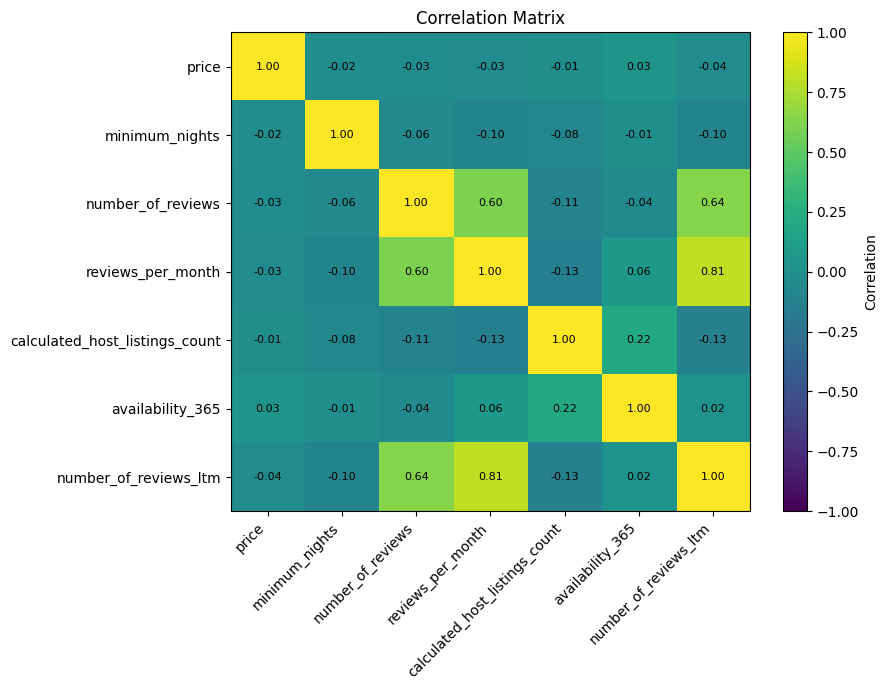

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
price,1.00,-0.02,-0.03,-0.03,-0.01,0.03,-0.04
minimum_nights,-0.02,1.00,-0.06,-0.10,-0.08,-0.01,-0.10
number_of_reviews,-0.03,-0.06,1.00,0.60,-0.11,-0.04,0.64
reviews_per_month,-0.03,-0.10,0.60,1.00,-0.13,0.06,0.81
calculated_host_listings_count,-0.01,-0.08,-0.11,-0.13,1.00,0.22,-0.13
availability_365,0.03,-0.01,-0.04,0.06,0.22,1.00,0.02
number_of_reviews_ltm,-0.04,-0.10,0.64,0.81,-0.13,0.02,1.00


In [20]:
correlation_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

corr = eda[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax, label="Correlation")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

corr

In [21]:
quality_checks = {
    "rows": len(eda),
    "columns": eda.shape[1],
    "fully_duplicated_rows": int(eda.duplicated().sum()),
    "duplicated_listing_ids": int(eda["id"].duplicated().sum()),
    "missing_prices": int(eda["price"].isna().sum()),
    "zero_or_negative_prices": int((eda["price"] <= 0).sum()),
    "missing_last_review": int(eda["last_review"].isna().sum()),
    "zero_total_reviews": int((eda["number_of_reviews"] == 0).sum()),
    "zero_availability": int((eda["availability_365"] == 0).sum())
}

pd.Series(quality_checks, name="value").to_frame()

,value
rows,17713
columns,19
fully_duplicated_rows,0
duplicated_listing_ids,0
missing_prices,1197
zero_or_negative_prices,0
missing_last_review,3456
zero_total_reviews,3456
zero_availability,756
